In [ ]:
print("Name: Divyadharshini S\nRoll no: 24BAD022")
import nltk
import string
from nltk.corpus import brown, stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

nltk.download('brown')
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

brown_sentences = brown.sents(categories='news')
print("Total sentences in Brown News Corpus:", len(brown_sentences))

print("\nSample Original Sentences:")
for sentence in brown_sentences[:3]:
    print(' '.join(sentence))

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess_text(sentence):
    text = ' '.join(sentence).lower()
    tokens = word_tokenize(text)
    tokens = [
        word for word in tokens
        if word.isalpha()
    ]
    tokens = [
        word for word in tokens
        if word not in stop_words
    ]
    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
    ]
    return tokens

processed_sentences = [
    preprocess_text(sentence)
    for sentence in brown_sentences
]

processed_sentences = [
    sentence for sentence in processed_sentences
    if sentence
]

print("\nOriginal Sentence:")
print(' '.join(brown_sentences[0]))

print("\nPreprocessed Sentence:")
print(processed_sentences[0])

print("\nNumber of sentences after preprocessing:",
      len(processed_sentences))


Name: Divyadharshini S
Roll no: 24BAD022


[nltk_data] Downloading package brown to /root/nltk_data...
[nltk_data]   Unzipping corpora/brown.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


Total sentences in Brown News Corpus: 4623

Sample Original Sentences:
The Fulton County Grand Jury said Friday an investigation of Atlanta's recent primary election produced `` no evidence '' that any irregularities took place .
The jury further said in term-end presentments that the City Executive Committee , which had over-all charge of the election , `` deserves the praise and thanks of the City of Atlanta '' for the manner in which the election was conducted .
The September-October term jury had been charged by Fulton Superior Court Judge Durwood Pye to investigate reports of possible `` irregularities '' in the hard-fought primary which was won by Mayor-nominate Ivan Allen Jr. .

Original Sentence:
The Fulton County Grand Jury said Friday an investigation of Atlanta's recent primary election produced `` no evidence '' that any irregularities took place .

Preprocessed Sentence:
['fulton', 'county', 'grand', 'jury', 'said', 'friday', 'investigation', 'atlanta', 'recent', 'primary'

Name: Divyadharshini S
Roll no: 24BAD022
Total processed words: 47682
Vocabulary size: 9896

Top 10 Most Frequent Words:
said: 406
year: 260
would: 249
new: 241
state: 223
one: 222
last: 177
two: 174
first: 158
president: 155


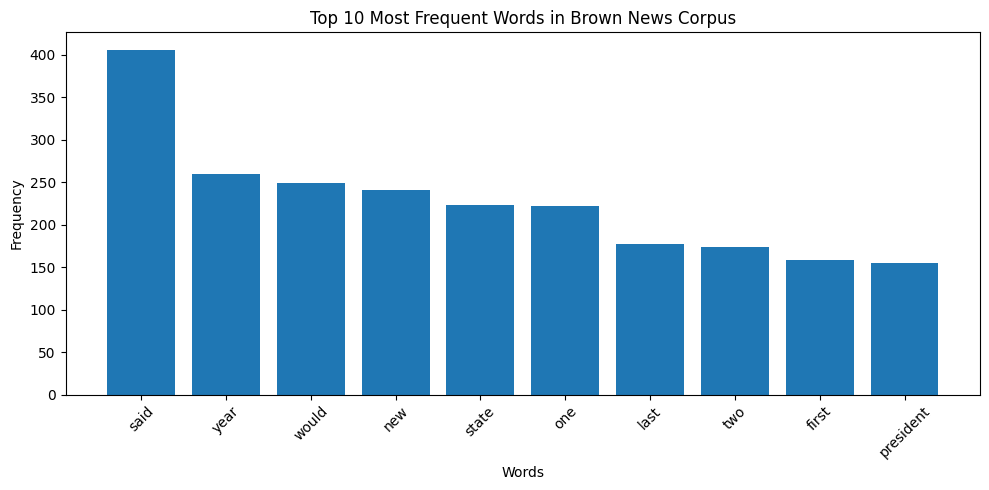


Sample Tokenized Sentences:
['fulton', 'county', 'grand', 'jury', 'said', 'friday', 'investigation', 'atlanta', 'recent', 'primary', 'election', 'produced', 'evidence', 'irregularity', 'took', 'place']
['jury', 'said', 'presentment', 'city', 'executive', 'committee', 'charge', 'election', 'deserves', 'praise', 'thanks', 'city', 'atlanta', 'manner', 'election', 'conducted']
['term', 'jury', 'charged', 'fulton', 'superior', 'court', 'judge', 'durwood', 'pye', 'investigate', 'report', 'possible', 'irregularity', 'primary', 'ivan', 'allen']
['relative', 'handful', 'report', 'received', 'jury', 'said', 'considering', 'widespread', 'interest', 'election', 'number', 'voter', 'size', 'city']
['jury', 'said', 'find', 'many', 'georgia', 'registration', 'election', 'law', 'outmoded', 'inadequate', 'often', 'ambiguous']


In [ ]:
print("Name: Divyadharshini S\nRoll no: 24BAD022")
from nltk.probability import FreqDist
import matplotlib.pyplot as plt

all_words = [
    word
    for sentence in processed_sentences
    for word in sentence
]

vocabulary = set(all_words)
print("Total processed words:", len(all_words))
print("Vocabulary size:", len(vocabulary))

freq_dist = FreqDist(all_words)
top_10_words = freq_dist.most_common(10)
print("\nTop 10 Most Frequent Words:")
for word, frequency in top_10_words:
    print(f"{word}: {frequency}")

words = [item[0] for item in top_10_words]
frequencies = [item[1] for item in top_10_words]

plt.figure(figsize=(10, 5))
plt.bar(words, frequencies)
plt.title("Top 10 Most Frequent Words in Brown News Corpus")
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("\nSample Tokenized Sentences:")
for sentence in processed_sentences[:5]:
    print(sentence)


In [ ]:
print("Name: Divyadharshini S\nRoll no: 24BAD022")
%pip install -q gensim
from gensim.models import Word2Vec

model = Word2Vec(
    sentences=processed_sentences,
    vector_size=100,
    window=5,
    min_count=2,
    sg=1,
    workers=4,
    epochs=10,
    seed=42
)

print("Word2Vec Skip-gram model trained successfully.")
print("Word2Vec vocabulary size:", len(model.wv))

selected_word = 'government'
if selected_word not in model.wv:
    selected_word = model.wv.index_to_key[0]

word_vector = model.wv[selected_word]

print("\nSelected Word:", selected_word)
print("Word Vector:")
print(word_vector)
print("Vector Dimensions:", word_vector.shape[0])

print("\nFive Most Similar Words to", selected_word)
similar_words = model.wv.most_similar(
    selected_word,
    topn=5
)

for word, similarity in similar_words:
    print(f"{word}: {similarity:.4f}")


Name: Divyadharshini S
Roll no: 24BAD022
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 40.6 MB/s eta 0:00:00
Word2Vec Skip-gram model trained successfully.
Word2Vec vocabulary size: 5164

Selected Word: government
Word Vector:
[-0.05821211 -0.02329125  0.00568934  0.22281761 -0.10213251 -0.03135616
  0.13660794  0.24520715  0.16510215 -0.26470792 -0.3386171   0.04846626
 -0.06969289  0.33893773 -0.04971159 -0.21103816  0.04849158 -0.15221356
 -0.22173978  0.15430498  0.08139903  0.1540607  -0.05527835  0.19035394
 -0.12450261  0.01404111 -0.20309652  0.18744074 -0.14185913 -0.05968321
 -0.11425283 -0.22717732  0.09285656  0.04658344  0.08019216 -0.15937425
  0.23291577 -0.23643547 -0.0901683  -0.04613065 -0.07490619 -0.06531449
  0.21883087 -0.2195677   0.1354828   0.06790636  0.4055096   0.30130455
  0.33142617 -0.34096915 -0.05768748 -0.30720228 -0.10814061  0.04784175
  0.03010967  0.04897688 -0.14603393  0.03283009 -0.02038853  0.17623462
 -0.04132952  0.0009115  -0.2208

In [5]:
print("Name: Divyadharshini S\nRoll no: 24BAD022\n")

from sklearn.metrics.pairwise import cosine_similarity
import numpy as np
word_pairs = [
    ('president', 'government'),
    ('city', 'state'),
    ('year', 'day')
]
similarity_results = []
print("Cosine Similarity Results:\n")

for word1, word2 in word_pairs:
    if word1 in model.wv and word2 in model.wv:
        vector1 = model.wv[word1].reshape(1, -1)
        vector2 = model.wv[word2].reshape(1, -1)
        score = cosine_similarity(vector1, vector2)[0][0]
        similarity_results.append((word1, word2, score))
        print(f"{word1} - {word2}: {score:.4f}")
    else:
        print(
            f"{word1} - {word2}: "
            "One or both words are missing from the vocabulary."
        )

if similarity_results:
    similarity_results.sort(key=lambda item: item[2], reverse=True)
    print("\nWord Pairs Ranked by Similarity:")
    for word1, word2, score in similarity_results:
        print(f"{word1} - {word2}: {score:.4f}")
    highest_pair = similarity_results[0]
    print("\nMost Similar Pair:")
    print(f"{highest_pair[0]} - {highest_pair[1]}")
    print(f"Cosine Similarity: {highest_pair[2]:.4f}")
else:
    print("No valid word pairs were found.")


Name: Divyadharshini S
Roll no: 24BAD022

Cosine Similarity Results:

president - government: 0.8487
city - state: 0.7697
year - day: 0.8999

Word Pairs Ranked by Similarity:
year - day: 0.8999
president - government: 0.8487
city - state: 0.7697

Most Similar Pair:
year - day
Cosine Similarity: 0.8999
